In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

project_root = Path.home() / "Documents" / "airline-delay-reliability-analysis"

monthly_dir = project_root / "data" / "processed" / "monthly"
figures_dir = project_root / "figures"

figures_dir.mkdir(parents=True, exist_ok=True)

parquet_files = sorted(monthly_dir.glob("flights_2025_*.parquet"))

print(f"Parquet files found: {len(parquet_files)}")

for file in parquet_files:
    print(file.name)

Parquet files found: 12
flights_2025_01.parquet
flights_2025_02.parquet
flights_2025_03.parquet
flights_2025_04.parquet
flights_2025_05.parquet
flights_2025_06.parquet
flights_2025_07.parquet
flights_2025_08.parquet
flights_2025_09.parquet
flights_2025_10.parquet
flights_2025_11.parquet
flights_2025_12.parquet


In [2]:
root_cause_columns = [
    "FlightDate",
    "Month",
    "DayOfWeek",
    "Marketing_Airline_Network",
    "Origin",
    "Dest",
    "CRSDepTime",
    "ArrDelayMinutes",
    "ArrDel15",
    "Cancelled",
    "Diverted",
    "CarrierDelay",
    "WeatherDelay",
    "NASDelay",
    "SecurityDelay",
    "LateAircraftDelay"
]

monthly_dfs = []

for file in parquet_files:
    month_df = pd.read_parquet(
        file,
        columns=root_cause_columns,
        engine="pyarrow"
    )
    monthly_dfs.append(month_df)

root_cause_df = pd.concat(
    monthly_dfs,
    ignore_index=True
)

memory_mb = root_cause_df.memory_usage(deep=True).sum() / 1024**2

print(f"Rows: {root_cause_df.shape[0]:,}")
print(f"Columns: {root_cause_df.shape[1]}")
print(f"Memory usage: {memory_mb:.2f} MB")
print(
    f"Date range: {root_cause_df['FlightDate'].min()} "
    f"to {root_cause_df['FlightDate'].max()}"
)

Rows: 4,518,993
Columns: 16
Memory usage: 586.11 MB
Date range: 2025-01-01 00:00:00 to 2025-12-31 00:00:00


In [3]:
delay_cause_columns = [
    "CarrierDelay",
    "WeatherDelay",
    "NASDelay",
    "SecurityDelay",
    "LateAircraftDelay"
]

print("ArrDel15 distribution:")
print(root_cause_df["ArrDel15"].value_counts(dropna=False))

print("\nNon-null counts for delay causes:")
print(
    root_cause_df[delay_cause_columns]
    .notna()
    .sum()
)

print("\nFlights with any delay cause recorded:")
has_delay_cause = root_cause_df[delay_cause_columns].notna().any(axis=1)

print(has_delay_cause.value_counts())

print("\nCross-check with ArrDel15:")
print(
    pd.crosstab(
        root_cause_df["ArrDel15"],
        has_delay_cause,
        dropna=False
    )
)

ArrDel15 distribution:
ArrDel15
0.0    3456473
1.0     973775
NaN      88745
Name: count, dtype: int64

Non-null counts for delay causes:
CarrierDelay         973775
WeatherDelay         973775
NASDelay             973775
SecurityDelay        973775
LateAircraftDelay    973775
dtype: int64

Flights with any delay cause recorded:
False    3545218
True      973775
Name: count, dtype: int64

Cross-check with ArrDel15:
col_0       False   True 
ArrDel15                 
0.0       3456473       0
1.0             0  973775
NaN         88745       0


In [4]:
delay_cause_summary = pd.DataFrame({
    "delay_cause": delay_cause_columns,
    "total_delay_minutes": [
        root_cause_df[col].sum()
        for col in delay_cause_columns
    ],
    "affected_flights": [
        (root_cause_df[col] > 0).sum()
        for col in delay_cause_columns
    ]
})

total_cause_minutes = delay_cause_summary["total_delay_minutes"].sum()

delay_cause_summary["delay_share_pct"] = (
    delay_cause_summary["total_delay_minutes"]
    / total_cause_minutes
    * 100
)

delay_cause_summary["avg_minutes_per_affected_flight"] = [
    root_cause_df.loc[root_cause_df[col] > 0, col].mean()
    for col in delay_cause_columns
]

delay_cause_summary = delay_cause_summary.sort_values(
    "total_delay_minutes",
    ascending=False
).reset_index(drop=True)

delay_cause_summary["total_delay_minutes"] = (
    delay_cause_summary["total_delay_minutes"].round(0)
)

delay_cause_summary["delay_share_pct"] = (
    delay_cause_summary["delay_share_pct"].round(2)
)

delay_cause_summary["avg_minutes_per_affected_flight"] = (
    delay_cause_summary["avg_minutes_per_affected_flight"].round(2)
)

print(f"Total attributed delay minutes: {total_cause_minutes:,.0f}")

delay_cause_summary

Total attributed delay minutes: 76,925,980


,delay_cause,total_delay_minutes,affected_flights,delay_share_pct,avg_minutes_per_affected_flight
0,LateAircraftDelay,28338074.0,445539,36.84,63.60
1,CarrierDelay,26281753.0,510272,34.16,51.51
2,NASDelay,16324526.0,514174,21.22,31.75
3,WeatherDelay,5920532.0,78897,7.70,75.04
4,SecurityDelay,61095.0,1878,0.08,32.53


In [5]:
airline_cause_summary = (
    root_cause_df
    .groupby("Marketing_Airline_Network")[delay_cause_columns]
    .sum()
    .reset_index()
)

airline_cause_long = airline_cause_summary.melt(
    id_vars="Marketing_Airline_Network",
    value_vars=delay_cause_columns,
    var_name="delay_cause",
    value_name="total_delay_minutes"
)

airline_totals = (
    airline_cause_long
    .groupby("Marketing_Airline_Network")["total_delay_minutes"]
    .transform("sum")
)

airline_cause_long["delay_share_pct"] = (
    airline_cause_long["total_delay_minutes"]
    / airline_totals
    * 100
)

airline_cause_long["total_delay_minutes"] = (
    airline_cause_long["total_delay_minutes"].round(0)
)

airline_cause_long["delay_share_pct"] = (
    airline_cause_long["delay_share_pct"].round(2)
)

airline_cause_pivot = airline_cause_long.pivot(
    index="Marketing_Airline_Network",
    columns="delay_cause",
    values="delay_share_pct"
)

airline_cause_pivot

delay_cause,CarrierDelay,LateAircraftDelay,NASDelay,SecurityDelay,WeatherDelay
Marketing_Airline_Network,,,,,
AA,32.18,42.75,16.44,0.13,8.50
DL,43.00,28.94,20.62,0.06,7.38
UA,28.70,35.93,28.48,0.03,6.87


In [6]:
monthly_cause_summary = (
    root_cause_df
    .groupby("Month")[delay_cause_columns]
    .sum()
)

monthly_cause_pct = (
    monthly_cause_summary
    .div(monthly_cause_summary.sum(axis=1), axis=0)
    * 100
)

monthly_cause_pct = monthly_cause_pct.round(2)

monthly_cause_pct

,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
Month,,,,,
1,37.97,10.42,19.09,0.09,32.44
2,36.80,8.20,20.18,0.08,34.74
3,35.27,7.69,20.17,0.08,36.79
4,33.83,7.30,22.01,0.10,36.76
5,30.83,8.41,24.88,0.10,35.78
6,33.21,8.27,20.52,0.07,37.94
7,32.31,8.36,20.37,0.06,38.90
8,34.87,8.17,18.48,0.09,38.39
9,36.70,6.62,21.32,0.10,35.27


In [7]:
monthly_completed = (
    root_cause_df
    .groupby("Month")["ArrDel15"]
    .count()
)

monthly_cause_minutes = (
    root_cause_df
    .groupby("Month")[delay_cause_columns]
    .sum()
)

monthly_cause_intensity = (
    monthly_cause_minutes
    .div(monthly_completed, axis=0)
    * 1000
)

monthly_cause_intensity = monthly_cause_intensity.round(0)

monthly_cause_intensity

,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
Month,,,,,
1,5599.0,1537.0,2816.0,13.0,4784.0
2,5754.0,1282.0,3156.0,12.0,5432.0
3,5248.0,1145.0,3001.0,11.0,5475.0
4,5072.0,1094.0,3301.0,15.0,5513.0
5,5674.0,1547.0,4580.0,18.0,6586.0
6,7936.0,1977.0,4904.0,16.0,9066.0
7,8017.0,2074.0,5056.0,16.0,9655.0
8,6121.0,1434.0,3244.0,16.0,6739.0
9,4146.0,748.0,2408.0,11.0,3985.0


In [8]:
core_airports = [
    "ATL", "DFW", "DEN", "ORD",
    "CLT", "MIA", "PHX",
    "DTW", "MSP", "SLC",
    "JFK", "LGA",
    "IAH", "EWR", "SFO", "LAX"
]

airport_df = root_cause_df[
    root_cause_df["Origin"].isin(core_airports)
].copy()

airport_completed = (
    airport_df
    .groupby("Origin")["ArrDel15"]
    .count()
)

airport_delayed = (
    airport_df
    .groupby("Origin")["ArrDel15"]
    .sum()
)

airport_cause_minutes = (
    airport_df
    .groupby("Origin")[delay_cause_columns]
    .sum()
)

airport_cause_intensity = (
    airport_cause_minutes
    .div(airport_completed, axis=0)
    * 1000
)

airport_summary = airport_cause_intensity.copy()

airport_summary["delay_rate_pct"] = (
    airport_delayed
    / airport_completed
    * 100
)

airport_summary["completed_arrivals"] = airport_completed

airport_summary = airport_summary[
    [
        "completed_arrivals",
        "delay_rate_pct",
        "CarrierDelay",
        "WeatherDelay",
        "NASDelay",
        "SecurityDelay",
        "LateAircraftDelay"
    ]
]

airport_summary["delay_rate_pct"] = (
    airport_summary["delay_rate_pct"].round(2)
)

airport_summary[delay_cause_columns] = (
    airport_summary[delay_cause_columns].round(0)
)

airport_summary = airport_summary.sort_values(
    "delay_rate_pct",
    ascending=False
)

airport_summary

,completed_arrivals,delay_rate_pct,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
Origin,,,,,,,
DFW,289112,28.83,6478.0,1957.0,3136.0,24.0,9448.0
ORD,331771,26.54,6211.0,1794.0,4038.0,10.0,8611.0
MIA,95008,26.11,6356.0,1148.0,4099.0,31.0,7429.0
LGA,135968,26.09,5365.0,804.0,5841.0,16.0,8243.0
EWR,109872,25.33,5017.0,1009.0,4838.0,3.0,9880.0
DEN,198591,23.39,5164.0,1057.0,3682.0,9.0,6957.0
CLT,228560,23.21,4561.0,1361.0,2678.0,33.0,7572.0
ATL,294925,22.92,6775.0,1488.0,3160.0,14.0,3944.0
DTW,120951,22.13,8414.0,1271.0,3492.0,8.0,3420.0


In [9]:
def get_time_band(crs_dep_time):
    if 500 <= crs_dep_time < 800:
        return "Early Morning"
    elif 800 <= crs_dep_time < 1100:
        return "Morning"
    elif 1100 <= crs_dep_time < 1400:
        return "Midday"
    elif 1400 <= crs_dep_time < 1700:
        return "Afternoon"
    elif 1700 <= crs_dep_time < 2000:
        return "Evening"
    else:
        return "Night"


root_cause_df["departure_time_band"] = (
    root_cause_df["CRSDepTime"].apply(get_time_band)
)

time_order = [
    "Early Morning",
    "Morning",
    "Midday",
    "Afternoon",
    "Evening",
    "Night"
]

time_completed = (
    root_cause_df
    .groupby("departure_time_band")["ArrDel15"]
    .count()
)

time_delayed = (
    root_cause_df
    .groupby("departure_time_band")["ArrDel15"]
    .sum()
)

time_cause_minutes = (
    root_cause_df
    .groupby("departure_time_band")[delay_cause_columns]
    .sum()
)

time_cause_intensity = (
    time_cause_minutes
    .div(time_completed, axis=0)
    * 1000
)

time_summary = time_cause_intensity.copy()

time_summary["delay_rate_pct"] = (
    time_delayed / time_completed * 100
)

time_summary = time_summary[
    [
        "delay_rate_pct",
        "CarrierDelay",
        "WeatherDelay",
        "NASDelay",
        "SecurityDelay",
        "LateAircraftDelay"
    ]
]

time_summary = time_summary.reindex(time_order)

time_summary["delay_rate_pct"] = (
    time_summary["delay_rate_pct"].round(2)
)

time_summary[delay_cause_columns] = (
    time_summary[delay_cause_columns].round(0)
)

time_summary

,delay_rate_pct,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
departure_time_band,,,,,,
Early Morning,12.14,6258.0,926.0,2051.0,10.0,1745.0
Morning,16.33,4834.0,768.0,2604.0,8.0,3571.0
Midday,20.47,4802.0,1035.0,3468.0,13.0,6166.0
Afternoon,26.87,5850.0,1612.0,5355.0,14.0,8358.0
Evening,31.13,6947.0,1968.0,5516.0,18.0,10907.0
Night,27.02,7824.0,2026.0,2779.0,23.0,8483.0


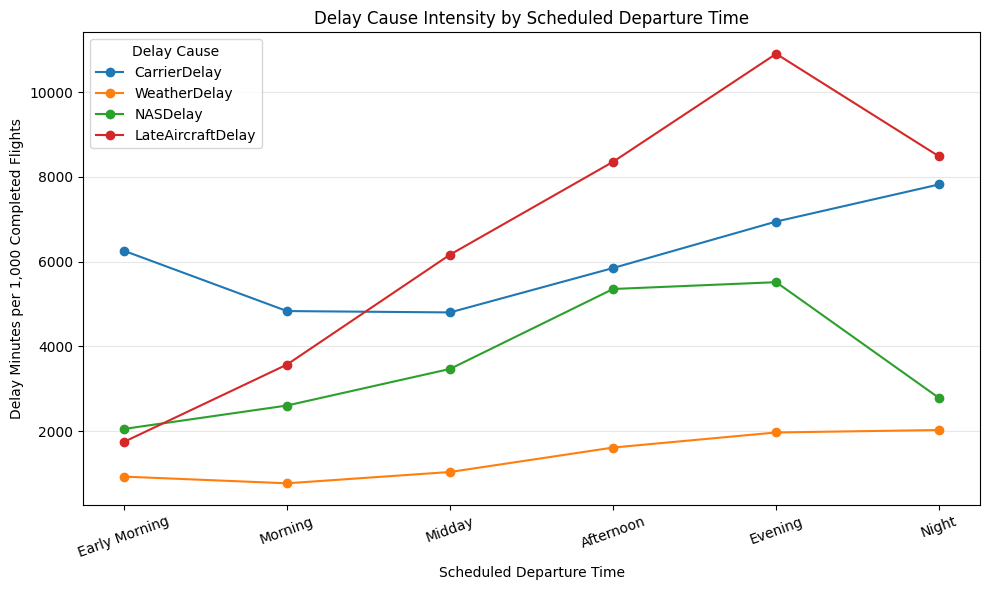

Saved to: C:\Users\21129\Documents\airline-delay-reliability-analysis\figures\delay_cause_intensity_by_time.png


In [10]:
plot_df = time_summary[
    [
        "CarrierDelay",
        "WeatherDelay",
        "NASDelay",
        "LateAircraftDelay"
    ]
]

ax = plot_df.plot(
    kind="line",
    marker="o",
    figsize=(10, 6)
)

ax.set_title("Delay Cause Intensity by Scheduled Departure Time")
ax.set_xlabel("Scheduled Departure Time")
ax.set_ylabel("Delay Minutes per 1,000 Completed Flights")
ax.legend(title="Delay Cause")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=20)
plt.tight_layout()

output_path = figures_dir / "delay_cause_intensity_by_time.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Saved to: {output_path}")

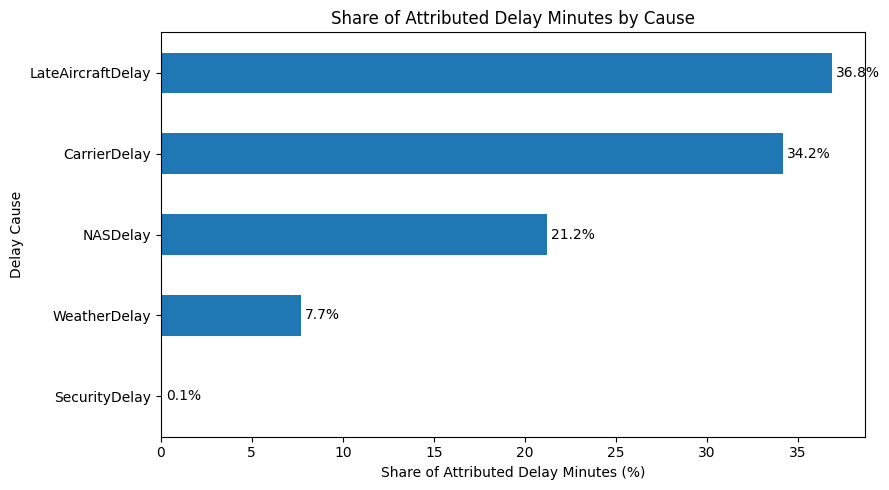

Saved to: C:\Users\21129\Documents\airline-delay-reliability-analysis\figures\overall_delay_cause_share.png


In [11]:
cause_plot_df = delay_cause_summary.copy()

cause_plot_df = cause_plot_df.sort_values(
    "delay_share_pct",
    ascending=True
)

ax = cause_plot_df.plot(
    x="delay_cause",
    y="delay_share_pct",
    kind="barh",
    figsize=(9, 5),
    legend=False
)

ax.set_title("Share of Attributed Delay Minutes by Cause")
ax.set_xlabel("Share of Attributed Delay Minutes (%)")
ax.set_ylabel("Delay Cause")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.tight_layout()

output_path = figures_dir / "overall_delay_cause_share.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Saved to: {output_path}")

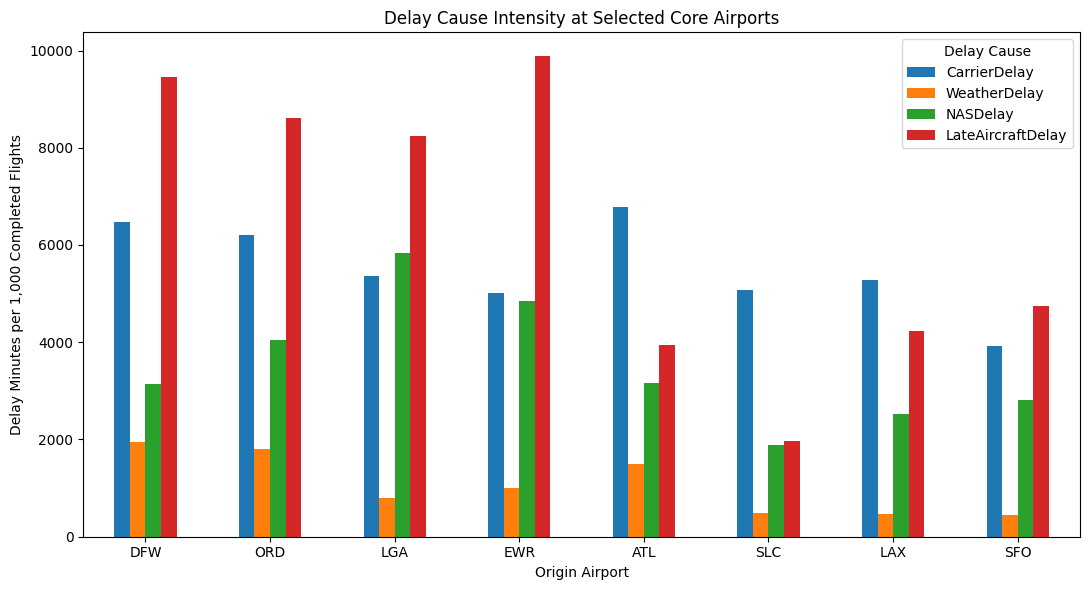

Saved to: C:\Users\21129\Documents\airline-delay-reliability-analysis\figures\airport_delay_cause_intensity.png


In [12]:
selected_airports = [
    "DFW", "ORD", "LGA", "EWR",
    "ATL", "SLC", "LAX", "SFO"
]

airport_plot_df = airport_summary.loc[
    selected_airports,
    [
        "CarrierDelay",
        "WeatherDelay",
        "NASDelay",
        "LateAircraftDelay"
    ]
]

ax = airport_plot_df.plot(
    kind="bar",
    figsize=(11, 6)
)

ax.set_title("Delay Cause Intensity at Selected Core Airports")
ax.set_xlabel("Origin Airport")
ax.set_ylabel("Delay Minutes per 1,000 Completed Flights")
ax.legend(title="Delay Cause")

plt.xticks(rotation=0)
plt.tight_layout()

output_path = figures_dir / "airport_delay_cause_intensity.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Saved to: {output_path}")

In [13]:
day3_findings = """# Day 3 - Delay Root Cause Analysis: Key Findings

## 1. Overall Delay Drivers

A total of 76.93 million attributed delay minutes were recorded among flights with arrival delays of at least 15 minutes.

- Late Aircraft Delay: 36.84%
- Carrier Delay: 34.16%
- NAS Delay: 21.22%
- Weather Delay: 7.70%
- Security Delay: 0.08%

Late Aircraft Delay and Carrier Delay together account for approximately 71% of attributed delay minutes.

## 2. Airline-Level Root Cause Differences

The three airline networks show different delay structures.

- AA has the highest share of Late Aircraft Delay at 42.75%.
- DL has the highest Carrier Delay share at 43.00%.
- UA has the highest NAS Delay share at 28.48%.

These results suggest that operational reliability problems differ materially across airline networks.

## 3. Seasonal Delay Patterns

June, July, and December show substantially higher delay intensity than September.

July recorded approximately:

- 9,655 Late Aircraft Delay minutes per 1,000 completed flights
- 8,017 Carrier Delay minutes
- 5,056 NAS Delay minutes
- 2,074 Weather Delay minutes

The deterioration during high-delay months is therefore not explained by weather alone.

## 4. Airport-Level Root Causes

Core airports exhibit different delay mechanisms.

- DFW shows strong Late Aircraft Delay intensity.
- ORD combines high Late Aircraft and NAS delay intensity.
- LGA has particularly high NAS Delay exposure.
- EWR shows very high Late Aircraft Delay intensity together with substantial NAS exposure.
- ATL has a relatively stronger Carrier Delay component.
- SLC provides a useful benchmark for comparatively lower delay intensity.

Airport reliability problems therefore require differentiated interventions rather than a single network-wide solution.

## 5. Intraday Delay Accumulation

Delay risk increases materially throughout the operating day.

Arrival delay rates increase from:

- 12.14% in Early Morning
- 16.33% in Morning
- 20.47% at Midday
- 26.87% in Afternoon
- 31.13% in Evening

Late Aircraft Delay intensity rises from approximately 1,745 minutes per 1,000 completed flights in Early Morning to 10,907 minutes in Evening.

This pattern is consistent with intraday delay propagation, which will be investigated directly using aircraft tail numbers in the network analysis stage.

## Business Implication

The results indicate that airline reliability improvement should focus on operational resilience, aircraft rotation, schedule recovery, and airport-specific intervention strategies rather than treating delay primarily as a weather-driven problem.
"""

docs_dir = project_root / "docs"
docs_dir.mkdir(parents=True, exist_ok=True)

findings_path = docs_dir / "day3_root_cause_findings.md"

findings_path.write_text(
    day3_findings,
    encoding="utf-8"
)

print(f"Saved to: {findings_path}")

Saved to: C:\Users\21129\Documents\airline-delay-reliability-analysis\docs\day3_root_cause_findings.md
